In [1]:
from pathlib import Path
import os, json, math, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import soundfile as sf
import librosa

from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)
from hmmlearn import hmm

SEED = 42
np.random.seed(SEED)

# Sửa dòng này nếu thư mục dataset nằm ở vị trí khác
PROJECT_DIR = Path(r"D:\SpeechAndAudio\TH3")
DATA_DIR = PROJECT_DIR / "data"
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"
RESULTS_DIR = PROJECT_DIR / "results"
MODELS_DIR = PROJECT_DIR / "models"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

LABEL_DIRS = {
    "mo": "mở",
    "dong": "đóng",
    "len": "lên",
    "xuong": "xuống",
    "dung": "dừng",
}
LABELS = list(LABEL_DIRS.keys())

SAMPLE_RATE = 16000
N_MFCC = 13
N_FFT = 400           # 25 ms ở 16 kHz
HOP_LENGTH = 160      # 10 ms ở 16 kHz
N_STATES = 5
COVARIANCE_TYPE = "diag"

print("Project:", PROJECT_DIR.resolve())
print("Dataset:", DATA_DIR.resolve())
print("Results:", RESULTS_DIR.resolve())

Project: D:\SpeechAndAudio\TH3
Dataset: D:\SpeechAndAudio\TH3\data
Results: D:\SpeechAndAudio\TH3\results


In [2]:
#Kiểm tra dữ liệu
def list_wavs(split_dir: Path):
    rows = []
    for folder_name, vietnamese_label in LABEL_DIRS.items():
        class_dir = split_dir / folder_name
        if not class_dir.exists():
            warnings.warn(f"Thiếu thư mục: {class_dir}")
            continue
        for p in sorted(class_dir.glob("*.wav")):
            try:
                info = sf.info(str(p))
                rows.append({
                    "path": str(p.resolve()),
                    "filename": p.name,
                    "label": folder_name,
                    "label_vi": vietnamese_label,
                    "split": split_dir.name,
                    "sample_rate": info.samplerate,
                    "channels": info.channels,
                    "frames": info.frames,
                    "duration_sec": info.duration,
                    "subtype": info.subtype,
                })
            except Exception as e:
                rows.append({
                    "path": str(p.resolve()), "filename": p.name,
                    "label": folder_name, "label_vi": vietnamese_label,
                    "split": split_dir.name, "error": str(e)
                })
    return rows

manifest_rows = list_wavs(TRAIN_DIR) + list_wavs(TEST_DIR)
manifest = pd.DataFrame(manifest_rows)
if manifest.empty:
    raise FileNotFoundError(
        f"Không tìm thấy WAV. Hãy kiểm tra DATA_DIR hiện là: {DATA_DIR.resolve()}"
    )

display(manifest.head(10))
print("\nSố file theo split và nhãn:")
display(manifest.groupby(["split", "label"]).size().unstack(fill_value=0))

if "error" in manifest.columns and manifest["error"].notna().any():
    display(manifest[manifest["error"].notna()][["path", "error"]])

manifest.to_csv(RESULTS_DIR / "audio_manifest.csv", index=False, encoding="utf-8-sig")

,path,filename,label,label_vi,split,sample_rate,channels,frames,duration_sec,subtype
0,D:\SpeechAndAudio\TH3\data\train\mo\mo_1.wav,mo_1.wav,mo,mở,train,16000,1,25941,1.621312,PCM_16
1,D:\SpeechAndAudio\TH3\data\train\mo\mo_2.wav,mo_2.wav,mo,mở,train,16000,1,27307,1.706687,PCM_16
2,D:\SpeechAndAudio\TH3\data\train\mo\mo_3.wav,mo_3.wav,mo,mở,train,16000,1,24576,1.536000,PCM_16
3,D:\SpeechAndAudio\TH3\data\train\mo\mo_4.wav,mo_4.wav,mo,mở,train,16000,1,14677,0.917312,PCM_16
4,D:\SpeechAndAudio\TH3\data\train\mo\mo_5.wav,mo_5.wav,mo,mở,train,16000,1,15360,0.960000,PCM_16
5,D:\SpeechAndAudio\TH3\data\train\mo\mo_6.wav,mo_6.wav,mo,mở,train,16000,1,15360,0.960000,PCM_16
6,D:\SpeechAndAudio\TH3\data\train\dong\dong_1.wav,dong_1.wav,dong,đóng,train,16000,1,15360,0.960000,PCM_16
7,D:\SpeechAndAudio\TH3\data\train\dong\dong_2.wav,dong_2.wav,dong,đóng,train,16000,1,15019,0.938688,PCM_16
8,D:\SpeechAndAudio\TH3\data\train\dong\dong_3.wav,dong_3.wav,dong,đóng,train,16000,1,14677,0.917312,PCM_16
9,D:\SpeechAndAudio\TH3\data\train\dong\dong_4.wav,dong_4.wav,dong,đóng,train,16000,1,14677,0.917312,PCM_16



Số file theo split và nhãn:


label,dong,dung,len,mo,xuong
split,,,,,
test,2,2,2,2,2
train,6,6,6,6,6


In [3]:
#Kiểm tra
expected = {"train": 6, "test": 2}
counts = manifest.groupby(["split", "label"]).size()
issues = []
for split, expected_n in expected.items():
    for label in LABELS:
        n = int(counts.get((split, label), 0))
        if n != expected_n:
            issues.append(f"{split}/{label}: có {n} file, kỳ vọng {expected_n}")

if issues:
    print("Cần kiểm tra các mục sau:")
    print("\n".join("- " + x for x in issues))
else:
    print("OK: mỗi từ có đúng 6 file train và 2 file test.")

# Cảnh báo định dạng; notebook sẽ chuyển tín hiệu sang mono/16 kHz khi đọc.
if "sample_rate" in manifest:
    print("\nSample rate đang có:")
    display(manifest.groupby(["split", "sample_rate"]).size().rename("n_files").reset_index())
if "channels" in manifest:
    print("\nSố kênh đang có:")
    display(manifest.groupby(["split", "channels"]).size().rename("n_files").reset_index())

OK: mỗi từ có đúng 6 file train và 2 file test.

Sample rate đang có:


,split,sample_rate,n_files
0,test,16000,10
1,train,16000,30



Số kênh đang có:


,split,channels,n_files
0,test,1,10
1,train,1,30


c:\Users\fpt1174\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


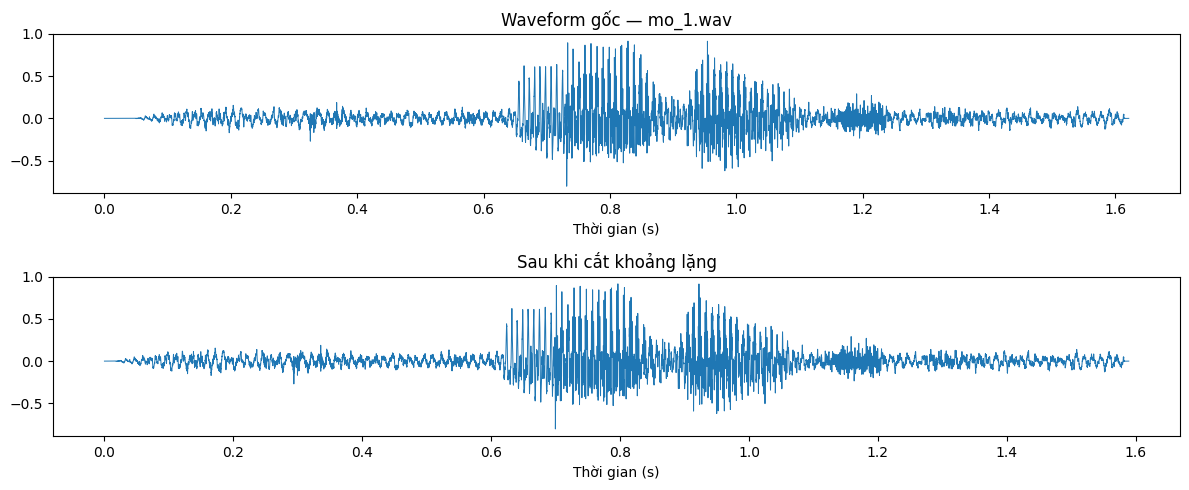

In [4]:
#Chuẩn hóa
def load_audio(path, target_sr=SAMPLE_RATE):
    y, sr = sf.read(str(path), dtype="float32", always_2d=True)
    # Trung bình các kênh thành mono
    y = y.mean(axis=1)
    if sr != target_sr:
        y = librosa.resample(y, orig_sr=sr, target_sr=target_sr)
        sr = target_sr
    y = np.asarray(y, dtype=np.float32)
    if len(y) == 0:
        raise ValueError(f"File âm thanh rỗng: {path}")
    # Bỏ DC offset
    y = y - np.mean(y)
    return y, sr

def trim_silence(y, top_db=30):
    trimmed, _ = librosa.effects.trim(y, top_db=top_db)
    # Không trả về mảng rỗng nếu bản ghi rất nhỏ
    return trimmed if len(trimmed) > 0 else y

# Thử đọc một mẫu và xem dạng sóng
example_path = Path(manifest.iloc[0]["path"])
y_example, sr_example = load_audio(example_path)
y_trim = trim_silence(y_example)

fig, axes = plt.subplots(2, 1, figsize=(12, 5))
axes[0].plot(np.arange(len(y_example))/sr_example, y_example, linewidth=0.7)
axes[0].set_title(f"Waveform gốc — {example_path.name}")
axes[0].set_xlabel("Thời gian (s)")
axes[1].plot(np.arange(len(y_trim))/sr_example, y_trim, linewidth=0.7)
axes[1].set_title("Sau khi cắt khoảng lặng")
axes[1].set_xlabel("Thời gian (s)")
plt.tight_layout()
plt.show()

In [5]:
#Trích xuất đặc trưng MFCC
def extract_features(path, n_mfcc=N_MFCC, use_deltas=True, apply_cmvn=True):
    y, sr = load_audio(path)
    y = trim_silence(y)
    # MFCC: (n_mfcc, frames)
    mfcc = librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=n_mfcc,
        n_fft=N_FFT, hop_length=HOP_LENGTH,
        n_mels=40, fmin=20, fmax=sr/2
    )
    feature_parts = [mfcc]
    if use_deltas:
        # Librosa delta cần số frame đủ lớn; mode nearest xử lý biên ổn định
        delta = librosa.feature.delta(mfcc, order=1, mode="nearest")
        delta2 = librosa.feature.delta(mfcc, order=2, mode="nearest")
        feature_parts.extend([delta, delta2])
    feats = np.concatenate(feature_parts, axis=0).T  # (T, 13 hoặc 39)
    if apply_cmvn:
        mean = feats.mean(axis=0, keepdims=True)
        std = feats.std(axis=0, keepdims=True)
        feats = (feats - mean) / np.maximum(std, 1e-6)
    return feats.astype(np.float64)

# Cache đặc trưng để không phải trích xuất lại ở mọi cell
feature_cache = {}
for row in manifest.to_dict("records"):
    if "error" in row:
        continue
    feature_cache[row["path"]] = extract_features(row["path"])

print(f"Đã trích xuất đặc trưng cho {len(feature_cache)} file.")
first_key = next(iter(feature_cache))
print("Kích thước mẫu đầu tiên (frames, features):", feature_cache[first_key].shape) 

Đã trích xuất đặc trưng cho 40 file.
Kích thước mẫu đầu tiên (frames, features): (159, 39)


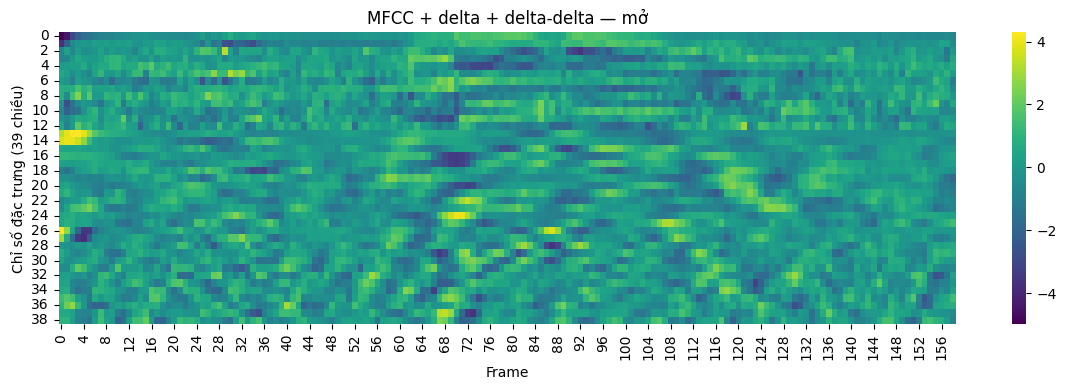

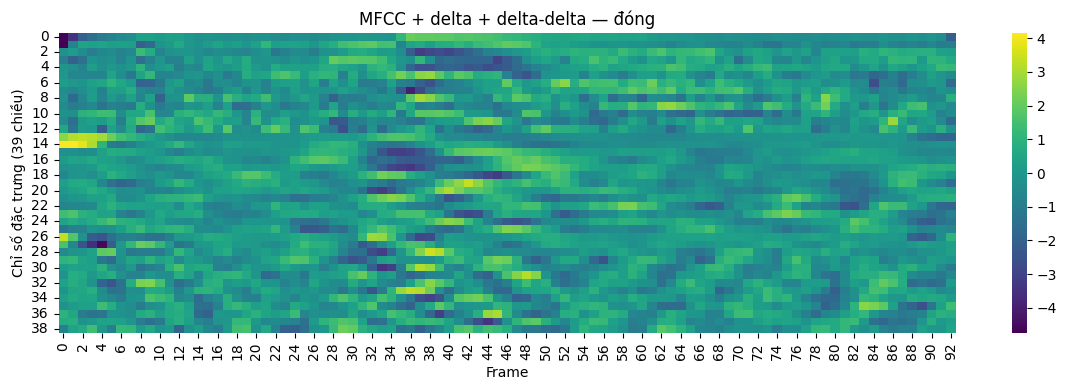

In [6]:
#Heatmap MFCC
def plot_feature_heatmap(path, title=None, max_frames=250):
    feats = feature_cache[str(Path(path).resolve())]
    plt.figure(figsize=(12, 4))
    sns.heatmap(feats[:max_frames].T, cmap="viridis", cbar=True)
    plt.xlabel("Frame")
    plt.ylabel("Chỉ số đặc trưng (39 chiều)")
    plt.title(title or Path(path).name)
    plt.tight_layout()
    out = RESULTS_DIR / f"heatmap_{Path(path).stem}.png"
    plt.savefig(out, dpi=160, bbox_inches="tight")
    plt.show()

for label in ["mo", "dong"]:
    subset = manifest[(manifest["split"] == "train") & (manifest["label"] == label)]
    if len(subset):
        plot_feature_heatmap(subset.iloc[0]["path"], f"MFCC + delta + delta-delta — {LABEL_DIRS[label]}")

In [7]:
#split data
def get_split_records(split):
    df = manifest[(manifest["split"] == split) & (~manifest["path"].isna())].copy()
    records = []
    for row in df.to_dict("records"):
        p = str(Path(row["path"]).resolve())
        if p in feature_cache:
            records.append({
                "path": p, "label": row["label"],
                "label_vi": row["label_vi"], "features": feature_cache[p]
            })
    return records

train_records = get_split_records("train")
test_records = get_split_records("test")

for split_name, records in [("train", train_records), ("test", test_records)]:
    print(split_name, ":", len(records), "utterances")
    print(pd.Series([r["label"] for r in records]).value_counts().reindex(LABELS, fill_value=0))

train : 30 utterances
mo       6
dong     6
len      6
xuong    6
dung     6
Name: count, dtype: int64
test : 10 utterances
mo       2
dong     2
len      2
xuong    2
dung     2
Name: count, dtype: int64


In [22]:
def make_left_right_hmm(
    n_states=5,
    covariance_type="diag",
    random_state=42
):
    model = hmm.GaussianHMM(
        n_components=n_states,
        covariance_type=covariance_type,
        n_iter=100,
        tol=1e-3,
        min_covar=1e-2,
        random_state=random_state,
        init_params="",
        params="stmc",
        transmat_prior=1.1,
        startprob_prior=1.1
    )

    # Chỉ bắt đầu ở trạng thái đầu tiên
    model.startprob_ = np.zeros(n_states)
    model.startprob_[0] = 1.0

    # Mỗi trạng thái có xác suất ở lại 0.7,
    # chuyển sang trạng thái kế tiếp với xác suất 0.3
    trans = np.zeros((n_states, n_states))

    for i in range(n_states - 1):
        trans[i, i] = 0.7
        trans[i, i + 1] = 0.3

    trans[-1, -1] = 1.0
    model.transmat_ = trans

    return model

In [23]:
#Huấn luyện mô hình HMM cho từng nhãn
def fit_word_hmm(
    label,
    records,
    n_states=5,
    covariance_type="diag"
):
    seqs = [
        r["features"]
        for r in records
        if r["label"] == label
    ]

    if len(seqs) < 2:
        raise ValueError(
            f"Không đủ mẫu train cho từ {label}"
        )

    # Kiểm tra đặc trưng đầu vào
    for i, x in enumerate(seqs):
        if x.ndim != 2:
            raise ValueError(f"Mẫu {i} không phải ma trận 2D")

        if not np.isfinite(x).all():
            raise ValueError(
                f"Mẫu {i} của {label} có NaN hoặc Inf"
            )

        if len(x) < n_states:
            raise ValueError(
                f"Mẫu {i} chỉ có {len(x)} frame, "
                f"nhỏ hơn số trạng thái {n_states}"
            )

    lengths = [len(x) for x in seqs]
    X = np.concatenate(seqs, axis=0)

    # Chia frame thành các vùng thời gian để khởi tạo
    # mean/covariance cho từng trạng thái.
    n_features = X.shape[1]
    boundaries = np.linspace(
        0, len(X), n_states + 1, dtype=int
    )

    means = []
    covars = []

    global_var = np.var(X, axis=0)
    global_var = np.maximum(global_var, 1e-2)

    for i in range(n_states):
        start = boundaries[i]
        end = boundaries[i + 1]

        segment = X[start:end]

        if len(segment) == 0:
            segment = X

        means.append(segment.mean(axis=0))

        if covariance_type == "diag":
            var = np.var(segment, axis=0)
            covars.append(np.maximum(var, 1e-2))

    model = make_left_right_hmm(
        n_states=n_states,
        covariance_type=covariance_type
    )

    model.means_ = np.asarray(means)

    if covariance_type == "diag":
        model.covars_ = np.asarray(covars)

    # Giữ đủ dữ liệu quan sát giữa các utterance
    model.fit(X, lengths)

    # Dừng ngay nếu tham số đã hỏng
    if not np.isfinite(model.means_).all():
        raise ValueError(
            f"Means của HMM {label} chứa NaN/Inf. "
            "Hãy giảm số trạng thái hoặc kiểm tra dữ liệu."
        )

    if not np.isfinite(model.transmat_).all():
        raise ValueError(
            f"Transmat của HMM {label} chứa NaN/Inf."
        )

    return model

In [24]:
#Kiểm tra ma trận chuyển trạng thái
for label, model in models.items():
    print(f"\n{LABEL_DIRS[label]} — startprob:")
    print(np.round(model.startprob_, 3))
    print("transmat:")
    print(np.round(model.transmat_, 3))
    backward_mass = np.tril(model.transmat_, k=-1).sum()
    print(f"Tổng xác suất chuyển lùi (dưới đường chéo): {backward_mass:.4f}")


mở — startprob:
[1. 0. 0. 0. 0.]
transmat:
[[0.    1.    0.    0.    0.   ]
 [0.    0.824 0.176 0.    0.   ]
 [0.    0.    0.976 0.024 0.   ]
 [0.    0.    0.    0.88  0.12 ]
 [0.    0.    0.    0.    1.   ]]
Tổng xác suất chuyển lùi (dưới đường chéo): 0.0000

đóng — startprob:
[1. 0. 0. 0. 0.]
transmat:
[[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]]
Tổng xác suất chuyển lùi (dưới đường chéo): 0.0000

lên — startprob:
[1. 0. 0. 0. 0.]
transmat:
[[0.    1.    0.    0.    0.   ]
 [0.    0.799 0.201 0.    0.   ]
 [0.    0.    0.956 0.044 0.   ]
 [0.    0.    0.    0.965 0.035]
 [0.    0.    0.    0.    1.   ]]
Tổng xác suất chuyển lùi (dưới đường chéo): 0.0000

xuống — startprob:
[1. 0. 0. 0. 0.]
transmat:
[[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]]
Tổng xác suất chuyển lùi (dưới đường chéo): 0.0000

dừng — startprob:
[1. 0. 0. 0. 0.]
transmat:
[[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]


In [25]:
# Sửa startprob_ và transmat_ của các HMM đã huấn luyện
for label, model in models.items():

    # 1. Sửa xác suất trạng thái đầu
    start = np.asarray(model.startprob_, dtype=np.float64)
    start = np.nan_to_num(start, nan=0.0, posinf=0.0, neginf=0.0)
    start = np.maximum(start, 0.0)

    if start.sum() <= 1e-12:
        start[:] = 0.0
        start[0] = 1.0

    model.startprob_ = start / start.sum()

    # 2. Sửa ma trận xác suất chuyển trạng thái
    trans = np.asarray(model.transmat_, dtype=np.float64)
    trans = np.nan_to_num(trans, nan=0.0, posinf=0.0, neginf=0.0)
    trans = np.maximum(trans, 0.0)

    for i in range(trans.shape[0]):
        row_sum = trans[i].sum()

        if row_sum <= 1e-12:
            # Nếu hàng không có xác suất hợp lệ, giữ trạng thái hiện tại
            trans[i, :] = 0.0
            trans[i, i] = 1.0
        else:
            trans[i, :] /= row_sum

    model.transmat_ = trans

    print(
        f"{label}: start sum={model.startprob_.sum():.6f}, "
        f"transmat row sums={np.round(model.transmat_.sum(axis=1), 6)}"
    )

print("\nĐã chuẩn hóa xác suất.")

mo: start sum=1.000000, transmat row sums=[1. 1. 1. 1. 1.]
dong: start sum=1.000000, transmat row sums=[1. 1. 1. 1. 1.]
len: start sum=1.000000, transmat row sums=[1. 1. 1. 1. 1.]
xuong: start sum=1.000000, transmat row sums=[1. 1. 1. 1. 1.]
dung: start sum=1.000000, transmat row sums=[1. 1. 1. 1. 1.]

Đã chuẩn hóa xác suất.


In [26]:
#Nhận dạng log-likelihood
def score_features(features, model_dict=models):
    return {label: float(model.score(features)) for label, model in model_dict.items()}

def predict_features(features, model_dict=models):
    scores = score_features(features, model_dict)
    pred = max(scores, key=scores.get)
    return pred, scores

prediction_rows = []
for rec in test_records:
    pred, scores = predict_features(rec["features"])
    row = {
        "filename": Path(rec["path"]).name,
        "path": rec["path"],
        "true_label": rec["label"],
        "true_label_vi": LABEL_DIRS[rec["label"]],
        "pred_label": pred,
        "pred_label_vi": LABEL_DIRS[pred],
        "correct": pred == rec["label"],
    }
    for label, score in scores.items():
        row[f"score_{label}"] = score
    prediction_rows.append(row)

pred_df = pd.DataFrame(prediction_rows)
display(pred_df)
pred_df.to_csv(RESULTS_DIR / "likelihood_scores.csv", index=False, encoding="utf-8-sig")

if len(pred_df):
    print("Test accuracy:", accuracy_score(pred_df["true_label"], pred_df["pred_label"]))

,filename,path,true_label,true_label_vi,pred_label,pred_label_vi,correct,score_mo,score_dong,score_len,score_xuong,score_dung
0,mo_7.wav,D:\SpeechAndAudio\TH3\data\test\mo\mo_7.wav,mo,mở,mo,mở,True,-5996.927978,NaN,-6954.939819,NaN,NaN
1,mo_8.wav,D:\SpeechAndAudio\TH3\data\test\mo\mo_8.wav,mo,mở,mo,mở,True,-6054.269080,NaN,-6605.652559,NaN,NaN
2,dong_7.wav,D:\SpeechAndAudio\TH3\data\test\dong\dong_7.wav,dong,đóng,len,lên,False,-5607.050977,NaN,-5599.513863,NaN,NaN
3,dong_8.wav,D:\SpeechAndAudio\TH3\data\test\dong\dong_8.wav,dong,đóng,len,lên,False,-5037.532002,NaN,-5016.688763,NaN,NaN
4,len_7.wav,D:\SpeechAndAudio\TH3\data\test\len\len_7.wav,len,lên,len,lên,True,-5512.539354,NaN,-5149.023773,NaN,NaN
5,len_8.wav,D:\SpeechAndAudio\TH3\data\test\len\len_8.wav,len,lên,len,lên,True,-6364.767706,NaN,-5894.633004,NaN,NaN
6,xuong_6.wav,D:\SpeechAndAudio\TH3\data\test\xuong\xuong_6.wav,xuong,xuống,len,lên,False,-6742.977290,NaN,-6649.932902,NaN,NaN
7,xuong_8.wav,D:\SpeechAndAudio\TH3\data\test\xuong\xuong_8.wav,xuong,xuống,mo,mở,False,-6980.924238,NaN,-7134.170329,NaN,NaN
8,dung_7.wav,D:\SpeechAndAudio\TH3\data\test\dung\dung_7.wav,dung,dừng,mo,mở,False,-4967.662134,NaN,-5086.986197,NaN,NaN
9,dung_8.wav,D:\SpeechAndAudio\TH3\data\test\dung\dung_8.wav,dung,dừng,len,lên,False,-6007.947163,NaN,-5819.100413,NaN,NaN


Test accuracy: 0.4


              precision    recall  f1-score   support

          mở       0.50      1.00      0.67         2
        đóng       0.00      0.00      0.00         2
         lên       0.33      1.00      0.50         2
       xuống       0.00      0.00      0.00         2
        dừng       0.00      0.00      0.00         2

    accuracy                           0.40        10
   macro avg       0.17      0.40      0.23        10
weighted avg       0.17      0.40      0.23        10



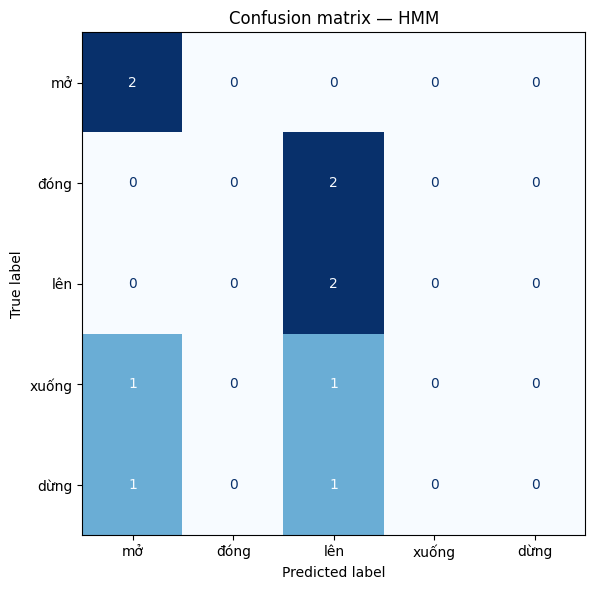

In [27]:
y_true = [r["label"] for r in test_records]
y_pred = [predict_features(r["features"])[0] for r in test_records]

print(classification_report(
    y_true, y_pred, labels=LABELS,
    target_names=[LABEL_DIRS[x] for x in LABELS],
    zero_division=0
))
cm = confusion_matrix(y_true, y_pred, labels=LABELS)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[LABEL_DIRS[x] for x in LABELS]
)
fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
plt.title("Confusion matrix — HMM")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrix_hmm.png", dpi=160, bbox_inches="tight")
plt.show()


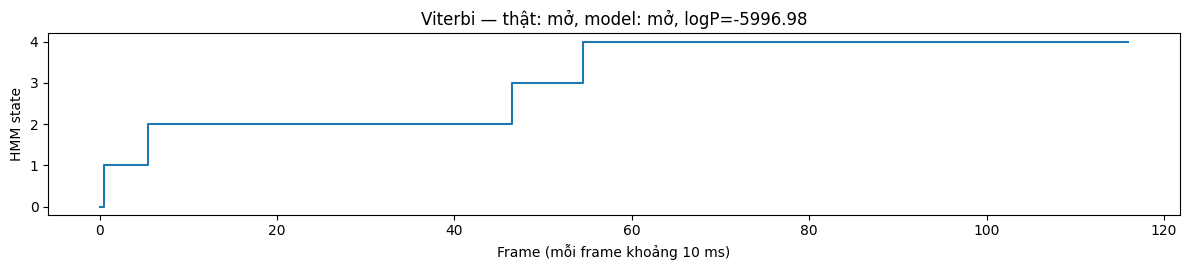

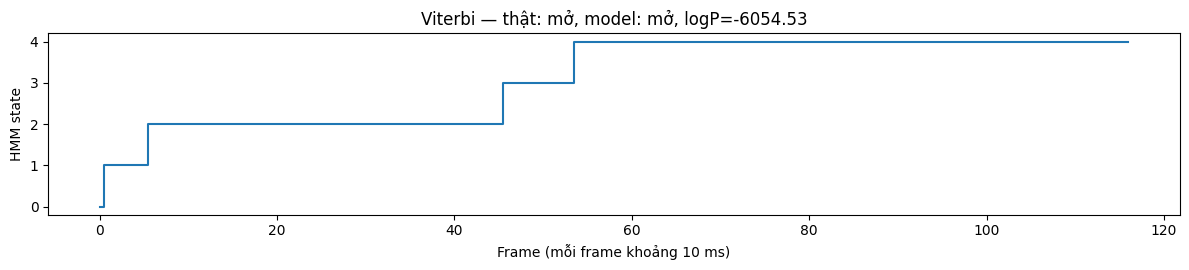

In [28]:
#Viterbi
def plot_viterbi_alignment(rec, model, label_name):
    X = rec["features"]
    logprob, state_path = model.decode(X, algorithm="viterbi")
    plt.figure(figsize=(12, 2.8))
    plt.step(np.arange(len(state_path)), state_path, where="mid")
    plt.yticks(range(model.n_components))
    plt.xlabel("Frame (mỗi frame khoảng 10 ms)")
    plt.ylabel("HMM state")
    plt.title(f"Viterbi — thật: {LABEL_DIRS[rec['label']]}, model: {LABEL_DIRS[label_name]}, logP={logprob:.2f}")
    plt.tight_layout()
    out = RESULTS_DIR / f"viterbi_{Path(rec['path']).stem}_{label_name}.png"
    plt.savefig(out, dpi=160, bbox_inches="tight")
    plt.show()

shown = 0
for rec in test_records:
    plot_viterbi_alignment(rec, models[rec["label"]], rec["label"])
    shown += 1
    if shown >= 2:
        break

In [29]:
#DTW Baseline
def extract_static_mfcc(path):
    # Dùng cùng pipeline audio nhưng chỉ MFCC 13 chiều, CMVN theo utterance
    return extract_features(path, n_mfcc=13, use_deltas=False, apply_cmvn=True)

static_cache = {}
for row in manifest.to_dict("records"):
    p = row.get("path")
    if p and p not in static_cache:
        static_cache[p] = extract_static_mfcc(p)

# Template là mẫu train đầu tiên của mỗi lớp; cố định để tái lập
templates = {}
for label in LABELS:
    candidates = [r for r in train_records if r["label"] == label]
    if not candidates:
        raise ValueError(f"Thiếu train template cho {label}")
    templates[label] = static_cache[candidates[0]["path"]]

def dtw_distance(x, y):
    # x,y shape: (T, features); librosa dtw nhận feature x feature×time
    D, wp = librosa.sequence.dtw(
        X=x.T, Y=y.T, metric="euclidean", subseq=False
    )
    return float(D[-1, -1] / max(len(wp), 1))

dtw_rows = []
for rec in test_records:
    x = static_cache[rec["path"]]
    distances = {label: dtw_distance(x, templates[label]) for label in LABELS}
    pred = min(distances, key=distances.get)
    row = {
        "filename": Path(rec["path"]).name,
        "true_label": rec["label"],
        "pred_label": pred,
        "correct": pred == rec["label"],
    }
    row.update({f"dtw_{k}": v for k, v in distances.items()})
    dtw_rows.append(row)

dtw_df = pd.DataFrame(dtw_rows)
display(dtw_df)
dtw_df.to_csv(RESULTS_DIR / "dtw_scores.csv", index=False, encoding="utf-8-sig")

hmm_acc = accuracy_score(y_true, y_pred) if y_true else float("nan")
dtw_pred = dtw_df["pred_label"].tolist()
dtw_acc = accuracy_score(dtw_df["true_label"], dtw_pred) if len(dtw_df) else float("nan")
comparison_df = pd.DataFrame([
    {"method": "HMM (39D MFCC)", "accuracy": hmm_acc, "n_test": len(y_true)},
    {"method": "DTW (13D MFCC, 1 template/class)", "accuracy": dtw_acc, "n_test": len(dtw_pred)},
])
display(comparison_df)
comparison_df.to_csv(RESULTS_DIR / "dtw_vs_hmm.csv", index=False, encoding="utf-8-sig")

,filename,true_label,pred_label,correct,dtw_mo,dtw_dong,dtw_len,dtw_xuong,dtw_dung
0,mo_7.wav,mo,mo,True,3.472906,3.934114,4.668721,4.275840,4.006064
1,mo_8.wav,mo,mo,True,3.313143,3.970873,4.324717,4.320351,4.057793
2,dong_7.wav,dong,mo,False,3.670997,3.818993,3.980905,4.226250,4.115136
3,dong_8.wav,dong,dong,True,3.821572,3.528137,4.053789,4.148924,3.897172
4,len_7.wav,len,len,True,4.146849,4.370536,3.681419,4.189852,3.923237
5,len_8.wav,len,len,True,4.127728,4.100449,3.302453,3.902818,3.880581
6,xuong_6.wav,xuong,xuong,True,4.177508,4.015454,3.965195,3.072665,3.791561
7,xuong_8.wav,xuong,xuong,True,4.038681,3.691357,3.950609,3.199627,3.603163
8,dung_7.wav,dung,dung,True,4.040476,4.580014,4.169548,4.068004,3.238811
9,dung_8.wav,dung,dung,True,4.057062,4.163894,4.070025,3.753114,3.061217


,method,accuracy,n_test
0,HMM (39D MFCC),0.4,10
1,"DTW (13D MFCC, 1 template/class)",0.9,10


In [30]:
#Đánh giá điều kiện khó và từ không biết
def add_white_noise(y, snr_db=15, seed=123):
    rng = np.random.default_rng(seed)
    signal_power = np.mean(y**2) + 1e-12
    noise_power = signal_power / (10**(snr_db / 10))
    noise = rng.normal(0, np.sqrt(noise_power), size=y.shape)
    return (y + noise).astype(np.float32)

robust_rows = []
for rec in test_records:
    y, sr = load_audio(rec["path"])
    y = trim_silence(y)
    noisy = add_white_noise(y, snr_db=15, seed=SEED)
    mfcc = librosa.feature.mfcc(
        y=noisy, sr=sr, n_mfcc=N_MFCC, n_fft=N_FFT,
        hop_length=HOP_LENGTH, n_mels=40, fmin=20, fmax=sr/2
    )
    feat_parts = [mfcc, librosa.feature.delta(mfcc, mode="nearest"),
                  librosa.feature.delta(mfcc, order=2, mode="nearest")]
    feats = np.concatenate(feat_parts, axis=0).T
    feats = (feats - feats.mean(axis=0, keepdims=True)) / np.maximum(feats.std(axis=0, keepdims=True), 1e-6)
    pred, scores = predict_features(feats)
    robust_rows.append({
        "filename": Path(rec["path"]).name,
        "true_label": rec["label"],
        "pred_label_noisy": pred,
        "correct_noisy": pred == rec["label"],
        "snr_db": 15,
        "max_loglik": max(scores.values()),
    })

robust_df = pd.DataFrame(robust_rows)
display(robust_df)
clean_acc = accuracy_score(y_true, y_pred) if y_true else np.nan
noisy_acc = accuracy_score(robust_df["true_label"], robust_df["pred_label_noisy"]) if len(robust_df) else np.nan
print(f"Clean accuracy: {clean_acc:.3f}; noisy (synthetic 15 dB) accuracy: {noisy_acc:.3f}")
robust_df.to_csv(RESULTS_DIR / "noise_robustness.csv", index=False, encoding="utf-8-sig")

# Reject-threshold demo:
# Điểm max log-likelihood phụ thuộc mô hình, độ dài và preprocessing; ngưỡng phải hiệu chỉnh
# bằng validation/unknown utterances độc lập, không thể xác lập tin cậy chỉ từ 10 test mẫu.
test_max_scores = pred_df[[f"score_{l}" for l in LABELS]].max(axis=1) if len(pred_df) else pd.Series(dtype=float)
if len(test_max_scores):
    print("Max log-likelihood trên test đã biết:")
    display(test_max_scores.describe().to_frame("max_loglik"))
    print("Không đặt ngưỡng reject cuối cùng nếu chưa có tập validation gồm lệnh ngoài từ vựng.")

,filename,true_label,pred_label_noisy,correct_noisy,snr_db,max_loglik
0,mo_7.wav,mo,mo,True,15,-6297.730961
1,mo_8.wav,mo,mo,True,15,-6301.842162
2,dong_7.wav,dong,len,False,15,-5919.251887
3,dong_8.wav,dong,mo,False,15,-5300.938241
4,len_7.wav,len,len,True,15,-5468.137255
5,len_8.wav,len,len,True,15,-5804.229714
6,xuong_6.wav,xuong,mo,False,15,-6847.232285
7,xuong_8.wav,xuong,mo,False,15,-7169.525330
8,dung_7.wav,dung,len,False,15,-5094.004236
9,dung_8.wav,dung,len,False,15,-6224.993036


Clean accuracy: 0.400; noisy (synthetic 15 dB) accuracy: 0.400
Max log-likelihood trên test đã biết:


,max_loglik
count,10.000000
mean,-5812.867615
std,666.532772
min,-6980.924238
25%,-6039.933805
50%,-5856.866709
75%,-5261.646295
max,-4967.662134


Không đặt ngưỡng reject cuối cùng nếu chưa có tập validation gồm lệnh ngoài từ vựng.


In [31]:
#Từ điển mini
# PLACEHOLDER DEMO ONLY — thay bằng phiên âm/phone inventory chuẩn của môn học.
lexicon_demo = {
    "mở": ["M", "O", "TONE_HOI"],
    "đóng": ["D", "O", "NG", "TONE_SAC"],
    "lên": ["L", "E", "N", "TONE_SAC"],
    "xuống": ["X", "UO", "NG", "TONE_SAC"],
    "dừng": ["D", "U", "NG", "TONE_HUYEN"],
}

lexicon_path = PROJECT_DIR / "lexicon.txt"
with open(lexicon_path, "w", encoding="utf-8") as f:
    for word, phones in lexicon_demo.items():
        f.write(word + " " + " ".join(phones) + "\n")

def load_lexicon(path):
    lex = {}
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            parts = line.split()
            if len(parts) >= 2:
                lex[parts[0]] = parts[1:]
    return lex

lexicon = load_lexicon(lexicon_path)
print("Lexicon demo:")
display(pd.DataFrame([
    {"word": w, "phones": " ".join(p)} for w, p in lexicon.items()
]))
print("Đã tạo:", lexicon_path)

Lexicon demo:


,word,phones
0,mở,M O TONE_HOI
1,đóng,D O NG TONE_SAC
2,lên,L E N TONE_SAC
3,xuống,X UO NG TONE_SAC
4,dừng,D U NG TONE_HUYEN


Đã tạo: D:\SpeechAndAudio\TH3\lexicon.txt


In [32]:
#Xây dựng unigram/bigram từ corpus câu lệnh
CORPUS_PATH = PROJECT_DIR / "corpus_commands.txt"
if not CORPUS_PATH.exists():
    CORPUS_PATH.write_text(
        "mở\n"
        "đóng\n"
        "lên\n"
        "xuống\n"
        "dừng\n"
        "mở lên\n"
        "mở xuống\n"
        "đóng lại\n"
        "dừng lại\n",
        encoding="utf-8"
    )

def read_corpus(path):
    return [
        [token.strip().lower() for token in line.split() if token.strip()]
        for line in Path(path).read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]

corpus = read_corpus(CORPUS_PATH)
unigram_counts = {}
bigram_counts = {}
context_counts = {}
vocab = set()

for sent in corpus:
    tokens = ["<s>"] + sent + ["</s>"]
    for token in tokens:
        unigram_counts[token] = unigram_counts.get(token, 0) + 1
        vocab.add(token)
    for a, b in zip(tokens[:-1], tokens[1:]):
        bigram_counts[(a, b)] = bigram_counts.get((a, b), 0) + 1
        context_counts[a] = context_counts.get(a, 0) + 1

def log_unigram(word, alpha=0.5):
    total = sum(unigram_counts.values())
    return math.log((unigram_counts.get(word, 0) + alpha) /
                    (total + alpha * len(vocab)))

def log_bigram(prev_word, word, alpha=0.5):
    V = len(vocab)
    num = bigram_counts.get((prev_word, word), 0) + alpha
    den = context_counts.get(prev_word, 0) + alpha * V
    return math.log(num / den)

def lm_logprob(words, order="bigram", alpha=0.5):
    tokens = ["<s>"] + list(words) + ["</s>"]
    if order == "unigram":
        return sum(log_unigram(w, alpha) for w in tokens[1:])
    return sum(log_bigram(a, b, alpha) for a, b in zip(tokens[:-1], tokens[1:]))

print("Số câu:", len(corpus), "| vocabulary size:", len(vocab))
print("Ví dụ log P('mở') unigram:", lm_logprob(["mở"], "unigram"))
print("Ví dụ log P('mở lên') bigram:", lm_logprob(["mở", "lên"], "bigram"))

Số câu: 9 | vocabulary size: 8
Ví dụ log P('mở') unigram: -3.606641355876964
Ví dụ log P('mở lên') bigram: -3.7281001672672174


In [33]:
#Rerank bằng trọng số mô hình ngôn ngữ
LAMBDA_VALUES = [0.0, 0.1, 0.3, 1.0]
lm_rows = []

for rec in test_records:
    acoustic_scores = score_features(rec["features"])
    # Câu lệnh ứng viên hiện tại là một từ; thay corpus/decoder nếu Lab yêu cầu chuỗi nhiều từ.
    for lam in LAMBDA_VALUES:
        combined = {}
        for label in LABELS:
            word = LABEL_DIRS[label]
            lm_score = lm_logprob([word], order="bigram")
            combined[label] = acoustic_scores[label] + lam * lm_score
        pred = max(combined, key=combined.get)
        lm_rows.append({
            "filename": Path(rec["path"]).name,
            "true_label": rec["label"],
            "lambda_lm": lam,
            "pred_label": pred,
            "correct": pred == rec["label"],
        })

lm_df = pd.DataFrame(lm_rows)
lm_summary = lm_df.groupby("lambda_lm")["correct"].mean().rename("accuracy").reset_index()
display(lm_summary)
lm_df.to_csv(RESULTS_DIR / "lm_reranking_detail.csv", index=False, encoding="utf-8-sig")
lm_summary.to_csv(RESULTS_DIR / "lm_reranking_summary.csv", index=False, encoding="utf-8-sig")

,lambda_lm,accuracy
0,0.0,0.4
1,0.1,0.4
2,0.3,0.4
3,1.0,0.4


In [34]:
#Thử nghiệm số trạng thái 3/5/7
state_experiment_rows = []
for n_states in [3, 5, 7]:
    exp_models = {}
    train_time = 0.0
    for label in LABELS:
        t0 = time.perf_counter()
        exp_models[label] = fit_word_hmm(label, train_records, n_states=n_states)
        train_time += time.perf_counter() - t0
    correct = 0
    total = 0
    for rec in test_records:
        pred, _ = predict_features(rec["features"], exp_models)
        correct += int(pred == rec["label"])
        total += 1
    state_experiment_rows.append({
        "n_states": n_states,
        "test_accuracy": correct / total if total else np.nan,
        "n_test": total,
        "total_train_seconds": train_time,
    })

state_experiments = pd.DataFrame(state_experiment_rows)
display(state_experiments)
state_experiments.to_csv(RESULTS_DIR / "experiment_n_states.csv", index=False, encoding="utf-8-sig")

,n_states,test_accuracy,n_test,total_train_seconds
0,3,0.8,10,0.140914
1,5,1.0,10,0.260768
2,7,1.0,10,0.246929


In [35]:
#So sánh MFCC 13 chiều và MFCC + delta + delta-delta 39 chiều
def fit_models_for_feature_setting(use_deltas):
    records = []
    for r in manifest.to_dict("records"):
        if "error" in r:
            continue
        records.append({
            "path": r["path"], "label": r["label"],
            "features": extract_features(r["path"], n_mfcc=13, use_deltas=use_deltas, apply_cmvn=True)
        })
    tr = [r for r in records if str(Path(r["path"])).startswith(str(TRAIN_DIR.resolve()))]
    te = [r for r in records if str(Path(r["path"])).startswith(str(TEST_DIR.resolve()))]
    ms = {label: fit_word_hmm(label, tr, n_states=N_STATES) for label in LABELS}
    correct = sum(predict_features(r["features"], ms)[0] == r["label"] for r in te)
    return correct / len(te) if te else np.nan

feature_experiment = pd.DataFrame([
    {"features": "MFCC 13D", "accuracy": fit_models_for_feature_setting(False)},
    {"features": "MFCC + delta + delta-delta 39D", "accuracy": fit_models_for_feature_setting(True)},
])
display(feature_experiment)
feature_experiment.to_csv(RESULTS_DIR / "experiment_feature_dims.csv", index=False, encoding="utf-8-sig")

,features,accuracy
0,MFCC 13D,1.0
1,MFCC + delta + delta-delta 39D,1.0


In [36]:
#Kết quả
summary = {
    "n_train": len(train_records),
    "n_test": len(test_records),
    "labels": {k: v for k, v in LABEL_DIRS.items()},
    "sample_rate_target": SAMPLE_RATE,
    "features_default": "13 MFCC + delta + delta-delta = 39D",
    "n_states_default": N_STATES,
    "hmm_test_accuracy": float(hmm_acc) if not pd.isna(hmm_acc) else None,
    "dtw_test_accuracy": float(dtw_acc) if not pd.isna(dtw_acc) else None,
    "warning": "Bộ test chỉ 2 mẫu/từ; accuracy dao động mạnh, không đủ để kết luận tổng quát hóa."
}
summary_path = RESULTS_DIR / "summary.json"
summary_path.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(summary, ensure_ascii=False, indent=2))
print("\nCác file kết quả:")
for p in sorted(RESULTS_DIR.glob("*")):
    print("-", p.name)

{
  "n_train": 30,
  "n_test": 10,
  "labels": {
    "mo": "mở",
    "dong": "đóng",
    "len": "lên",
    "xuong": "xuống",
    "dung": "dừng"
  },
  "sample_rate_target": 16000,
  "features_default": "13 MFCC + delta + delta-delta = 39D",
  "n_states_default": 5,
  "hmm_test_accuracy": 0.4,
  "dtw_test_accuracy": 0.9,
  "warning": "Bộ test chỉ 2 mẫu/từ; accuracy dao động mạnh, không đủ để kết luận tổng quát hóa."
}

Các file kết quả:
- audio_manifest.csv
- confusion_matrix_hmm.png
- dtw_scores.csv
- dtw_vs_hmm.csv
- experiment_feature_dims.csv
- experiment_n_states.csv
- heatmap_dong_1.png
- heatmap_mo_1.png
- likelihood_scores.csv
- lm_reranking_detail.csv
- lm_reranking_summary.csv
- noise_robustness.csv
- summary.json
- training_summary.csv
- viterbi_mo_7_mo.png
- viterbi_mo_8_mo.png
